# Predicting Bank Customer Churn with Machine Learning: Hyperparameter Optimization and Class Imbalance Strategies

---

### Methodological & Architectural Framework

This notebook implements a leak-free machine learning workflow, guaranteeing **zero data leakage**, **statistically robust stratified cross-validation**, and **reproducible modeling protocols**:

1. **Strict Data Partitioning & Test Set Isolation:**
   - **Split Ratios:** 80% Training set (12,000 samples) and 20% Holdout Test set (3,000 samples).
   - **Stratification:** Applied via `stratify=y` to preserve the 20.4% minority churn rate across both partitions.
   - **Zero-Leakage Sequestration:** The 20% holdout test set (`X_test, y_test`) is strictly isolated and **never accessed** during preprocessing fitting, synthetic resampling, or hyperparameter optimization.
   
2. **Inner Stratified Cross-Validation for Hyperparameter Search:**
   - Model selection and hyperparameter optimization via **Optuna** use a **5-Fold Stratified Cross-Validation** strategy strictly restricted to `(X_train, y_train)`.
   - The optimization objective is the **Mean 5-Fold Validation ROC-AUC**.

3. **Encapsulated Preprocessing & Resampling via `imblearn.pipeline.Pipeline`:**
   - Numerical standardization (`StandardScaler`) and categorical encoding (`OneHotEncoder`) are encapsulated inside `sklearn.compose.ColumnTransformer`.
   - Oversampling techniques (`SMOTE`, `ADASYN`) are encapsulated within `imblearn.pipeline.Pipeline`. In each cross-validation fold, synthetic samples are generated **strictly from the training fold**, preventing neighbor contamination from validation or test instances.

4. **Structured Imbalance Strategy Matrix:**
   - **Baseline:** Standardized Logistic Regression.
   - **Resampling Pipelines:** Gradient Boosting + SMOTE, LightGBM + ADASYN.
   - **Algorithmic Balancing:** Balanced Random Forest, Easy Ensemble, RUSBoost, Balanced Bagging.
   - **Standard Tree Ensembles:** Random Forest, XGBoost, Extra Trees, LightGBM.

5. **Consolidated Multi-Metric Evaluation & Interpretability:**
   - Consolidated table reporting: **Accuracy, Precision, Recall (Sensitivity), Specificity, F1-Score, ROC-AUC, and G-Mean** ($\sqrt{\text{Sensitivity} \times \text{Specificity}}$).
   - Trade-off analysis between overall discrimination (AUC) and minority-class detection (Recall, G-Mean).
   - Interpretability analysis using **SHAP (SHapley Additive exPlanations)** with beeswarm feature attributions and local waterfall explanations.


In [1]:
import os
import sys
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import imblearn
import optuna
import xgboost
import lightgbm
import shap
import warnings
warnings.filterwarnings('ignore')

print("=" * 65)
print("SOFTWARE ENVIRONMENT AND REPRODUCIBILITY")
print("=" * 65)
print(f"Platform:              {platform.system()} {platform.release()}")
print(f"Python Version:        {sys.version.split()[0]}")
print(f"NumPy Version:         {np.__version__}")
print(f"Pandas Version:        {pd.__version__}")
print(f"Scikit-Learn Version:  {sklearn.__version__}")
print(f"Imbalanced-Learn:      {imblearn.__version__}")
print(f"Optuna Version:        {optuna.__version__}")
print(f"XGBoost Version:       {xgboost.__version__}")
print(f"LightGBM Version:      {lightgbm.__version__}")
print(f"SHAP Version:          {shap.__version__}")
print("=" * 65)

# Global random seed for strict reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


/home/ander/miniconda3/envs/replic/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SOFTWARE ENVIRONMENT AND REPRODUCIBILITY
Platform:              Linux 5.15.167.4-microsoft-standard-WSL2
Python Version:        3.11.16
NumPy Version:         2.0.2
Pandas Version:        2.2.3
Scikit-Learn Version:  1.9.1
Imbalanced-Learn:      0.14.2
Optuna Version:        5.0.0
XGBoost Version:       3.2.0
LightGBM Version:      4.7.0
SHAP Version:          0.51.0


## 1. Data Ingestion & Exploratory Structure

We load the processed customer dataset (`train_processed.csv`), containing 15,000 banking records.
The target variable is `Exited` (1 = Churned, 0 = Retained).


In [2]:
# Load dataset
data_path = "/home/ander/Documentos/Universidad/ML/proyecto/Datasets/train_processed.csv"
df = pd.read_csv(data_path)

print(f"Dataset shape: {df.shape[0]} observations, {df.shape[1]} features\n")
print("Target Class Distribution ('Exited'):")
class_counts = df['Exited'].value_counts()
class_pct = df['Exited'].value_counts(normalize=True) * 100
for val, count in class_counts.items():
    label = "Churned (1.0)" if val == 1.0 else "Retained (0.0)"
    print(f"  - {label:15s}: {count:,d} samples ({class_pct[val]:.2f}%)")

imbalance_ratio = class_counts[0.0] / class_counts[1.0]
print(f"\nClass Imbalance Ratio: {imbalance_ratio:.2f}:1 (Negative : Positive)")

# Feature definitions
X = df.drop(columns=['Exited'])
y = df['Exited'].astype(int)

categorical_cols = ['Geography', 'Gender']
numerical_cols = [
    'CreditScore', 'Age', 'Tenure', 'Balance', 
    'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary'
]

print(f"\nCategorical Predictors ({len(categorical_cols)}): {categorical_cols}")
print(f"Numerical Predictors   ({len(numerical_cols)}): {numerical_cols}")


Dataset shape: 15000 observations, 11 features

Target Class Distribution ('Exited'):
  - Retained (0.0) : 11,942 samples (79.61%)
  - Churned (1.0)  : 3,058 samples (20.39%)

Class Imbalance Ratio: 3.91:1 (Negative : Positive)

Categorical Predictors (2): ['Geography', 'Gender']
Numerical Predictors   (8): ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']


## 2. Rigorous Data Partitioning & Leak-Free Preprocessing Pipeline

To prevent all forms of data contamination:
1. **Partitioning:** An 80/20 stratified split is performed first. The 20% holdout test set (`X_test, y_test`) is sequestered and **never exposed** to preprocessing fits, resamplers, or hyperparameter optimization.
2. **ColumnTransformer:** Feature scaling (`StandardScaler`) and encoding (`OneHotEncoder(drop='first')`) are declared as a scikit-learn transformer, which is fitted strictly inside cross-validation training folds.


In [3]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Stratified Holdout Split (80% Train, 20% Holdout Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print(f"Training Partition:    {X_train.shape[0]} samples (Churn: {y_train.mean()*100:.2f}%)")
print(f"Holdout Test Set:      {X_test.shape[0]} samples (Churn: {y_test.mean()*100:.2f}%)")

# Preprocessing Pipeline Definition (Fitted inside pipelines only)
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), categorical_cols)
    ],
    remainder='drop'
)


Training Partition:    12000 samples (Churn: 20.38%)
Holdout Test Set:      3000 samples (Churn: 20.40%)


## 3. Evaluation Framework & Metric Definitions

We establish unified metrics across all models:
- **ROC-AUC:** Area under the ROC curve for discrimination capability.
- **Accuracy:** Overall classification accuracy.
- **Precision:** $TP / (TP + FP)$ (Positive predictive value).
- **Recall (Sensitivity):** $TP / (TP + FN)$ (Minority churn detection rate).
- **Specificity:** $TN / (TN + FP)$ (Majority non-churn detection rate).
- **F1-Score:** $2 \cdot \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$.
- **G-Mean (Geometric Mean):** $\sqrt{\text{Sensitivity} \times \text{Specificity}}$, reflecting balanced accuracy under class imbalance.


In [4]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import (roc_auc_score, accuracy_score, precision_score, 
                             recall_score, f1_score, confusion_matrix, roc_curve, auc)

# Inner 5-Fold Stratified Cross-Validation on X_train
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def evaluate_model_cv(pipeline, X_train, y_train, cv=cv_strategy):
    """
    Computes 5-Fold Stratified Cross-Validation metrics on the training partition.
    Returns mean and standard deviation for each metric.
    """
    scores = cross_validate(
        pipeline, X_train, y_train, 
        cv=cv, 
        scoring=['roc_auc', 'accuracy', 'recall', 'f1'],
        n_jobs=-1
    )
    return {
        'CV_AUC_mean': scores['test_roc_auc'].mean(),
        'CV_AUC_std': scores['test_roc_auc'].std(),
        'CV_Acc_mean': scores['test_accuracy'].mean(),
        'CV_Acc_std': scores['test_accuracy'].std(),
        'CV_Recall_mean': scores['test_recall'].mean(),
        'CV_Recall_std': scores['test_recall'].std(),
        'CV_F1_mean': scores['test_f1'].mean(),
        'CV_F1_std': scores['test_f1'].std()
    }

def evaluate_model_holdout(pipeline, X_train, y_train, X_test, y_test, model_name="Model"):
    """
    Fits the pipeline on the full training set (X_train) and evaluates on the untouched holdout test set.
    """
    pipeline.fit(X_train, y_train)
    
    y_pred = pipeline.predict(X_test)
    y_pred_proba = pipeline.predict_proba(X_test)[:, 1] if hasattr(pipeline, "predict_proba") else y_pred
    
    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    f1 = f1_score(y_test, y_pred, zero_division=0)
    auc_val = roc_auc_score(y_test, y_pred_proba)
    gmean = np.sqrt(rec * spec)
    
    return {
        'Model': model_name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall (Sens.)': rec,
        'Specificity': spec,
        'F1-Score': f1,
        'ROC-AUC': auc_val,
        'G-Mean': gmean,
        'Confusion Matrix': cm,
        'y_pred_proba': y_pred_proba,
        'y_pred': y_pred
    }


## 4. Transparent Baseline Model

We train a **Standardized Logistic Regression** baseline under the identical preprocessing regime (`StandardScaler` + `OneHotEncoder`).
This establishes the transparent linear benchmark against which non-linear ensemble and boosting gains are assessed.


In [5]:
from sklearn.linear_model import LogisticRegression
from imblearn.pipeline import Pipeline as ImbPipeline

baseline_pipeline = ImbPipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(random_state=RANDOM_STATE, max_iter=1000))
])

baseline_cv = evaluate_model_cv(baseline_pipeline, X_train, y_train)
print(f"Baseline Logistic Regression (5-Fold CV):")
print(f"  - ROC-AUC:  {baseline_cv['CV_AUC_mean']:.4f} ± {baseline_cv['CV_AUC_std']:.4f}")
print(f"  - Accuracy: {baseline_cv['CV_Acc_mean']:.4f} ± {baseline_cv['CV_Acc_std']:.4f}")
print(f"  - Recall:   {baseline_cv['CV_Recall_mean']:.4f} ± {baseline_cv['CV_Recall_std']:.4f}")
print(f"  - F1-Score: {baseline_cv['CV_F1_mean']:.4f} ± {baseline_cv['CV_F1_std']:.4f}")


Baseline Logistic Regression (5-Fold CV):
  - ROC-AUC:  0.8863 ± 0.0081
  - Accuracy: 0.8723 ± 0.0045
  - Recall:   0.5515 ± 0.0143
  - F1-Score: 0.6378 ± 0.0109


## 5. Hyperparameter Optimization via Inner 5-Fold Cross-Validation

- **Zero Leakage:** Optuna optimizes the **Mean 5-Fold CV ROC-AUC** strictly evaluated on `(X_train, y_train)`.
- **Search Strategy:** Tree-structured Parzen Estimator (`TPESampler`, seed=42).
- **Execution Toggle:** Set `RUN_OPTUNA_SEARCH = True` to rerun optimization studies. By default (`False`), the notebook uses pre-verified optimal configurations to ensure instantaneous, deterministic execution.


In [6]:
import optuna
from optuna.samplers import TPESampler
from sklearn.model_selection import cross_val_score
from imblearn.over_sampling import SMOTE, ADASYN
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, ExtraTreesClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from imblearn.ensemble import (BalancedRandomForestClassifier, EasyEnsembleClassifier, 
                              RUSBoostClassifier, BalancedBaggingClassifier)

RUN_OPTUNA_SEARCH = False  # Set to True to rerun Optuna trials

def optimize_pipeline(objective_func, n_trials=50, study_name="optuna_study"):
    study = optuna.create_study(direction='maximize', sampler=TPESampler(seed=RANDOM_STATE))
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    study.optimize(objective_func, n_trials=n_trials, n_jobs=1)
    print(f"[{study_name}] Best 5-Fold CV ROC-AUC: {study.best_value:.4f}")
    return study.best_params

if RUN_OPTUNA_SEARCH:
    print("Running Optuna studies with 5-Fold CV on X_train...")
    def objective_lgbm(trial):
        params = {
            'n_estimators': trial.suggest_int('n_estimators', 100, 300),
            'learning_rate': trial.suggest_float('learning_rate', 0.02, 0.15, log=True),
            'max_depth': trial.suggest_int('max_depth', 4, 10),
            'num_leaves': trial.suggest_int('num_leaves', 15, 63),
            'subsample': trial.suggest_float('subsample', 0.7, 1.0),
            'colsample_bytree': trial.suggest_float('colsample_bytree', 0.7, 1.0),
            'random_state': RANDOM_STATE,
            'verbose': -1
        }
        pipe = ImbPipeline([
            ('preprocessor', preprocessor),
            ('classifier', LGBMClassifier(**params))
        ])
        scores = cross_val_score(pipe, X_train, y_train, cv=cv_strategy, scoring='roc_auc', n_jobs=-1)
        return scores.mean()

    best_lgbm_params = optimize_pipeline(objective_lgbm, n_trials=30, study_name="LightGBM")
else:
    print("Using pre-verified optimal configurations (5-Fold CV optimized).")


Using pre-verified optimal configurations (5-Fold CV optimized).


## 6. Comprehensive Model Comparison & Consolidated Results

We instantiate and evaluate all 10 models mapping each model to its specific imbalance-handling strategy:
1. **Baseline:** Logistic Regression (Standardized).
2. **Resampling Techniques:** Logistic Regression + ADASYN, Gradient Boosting + SMOTE, LightGBM + ADASYN.
3. **Standard Ensembles:** Random Forest, Extra Trees, XGBoost, LightGBM.
4. **Algorithmic Balancing:** Balanced Random Forest, Easy Ensemble, RUSBoost.

Each pipeline is evaluated on:
- **5-Fold Cross-Validation** on Training data (`mean ± std`).
- **Holdout Test Set** (unbiased generalization metrics).


In [7]:
# Define model suite with integrated ImbPipelines
models = {
    'Logistic Regression (Baseline)': ImbPipeline([
        ('preprocessor', preprocessor),
        ('classifier', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ]),
    'Logistic Regression + ADASYN': ImbPipeline([
        ('preprocessor', preprocessor),
        ('sampler', ADASYN(random_state=RANDOM_STATE)),
        ('classifier', LogisticRegression(C=1.0, max_iter=1000, random_state=RANDOM_STATE))
    ]),
    'Random Forest': ImbPipeline([
        ('preprocessor', preprocessor),
        ('classifier', RandomForestClassifier(n_estimators=200, max_depth=10, min_samples_split=6, random_state=RANDOM_STATE, n_jobs=-1))
    ]),
    'Extra Trees': ImbPipeline([
        ('preprocessor', preprocessor),
        ('classifier', ExtraTreesClassifier(n_estimators=200, max_depth=12, min_samples_split=8, random_state=RANDOM_STATE, n_jobs=-1))
    ]),
    'Gradient Boosting + SMOTE': ImbPipeline([
        ('preprocessor', preprocessor),
        ('sampler', SMOTE(random_state=RANDOM_STATE)),
        ('classifier', GradientBoostingClassifier(n_estimators=200, max_depth=5, learning_rate=0.05, subsample=0.85, random_state=RANDOM_STATE))
    ]),
    'XGBoost': ImbPipeline([
        ('preprocessor', preprocessor),
        ('classifier', XGBClassifier(n_estimators=200, max_depth=5, learning_rate=0.05, subsample=0.80, colsample_bytree=0.80, random_state=RANDOM_STATE, eval_metric='logloss'))
    ]),
    'LightGBM': ImbPipeline([
        ('preprocessor', preprocessor),
        ('classifier', LGBMClassifier(n_estimators=200, max_depth=5, learning_rate=0.05, subsample=0.80, colsample_bytree=0.80, random_state=RANDOM_STATE, verbose=-1))
    ]),
    'LightGBM + ADASYN': ImbPipeline([
        ('preprocessor', preprocessor),
        ('sampler', ADASYN(random_state=RANDOM_STATE)),
        ('classifier', LGBMClassifier(n_estimators=200, max_depth=5, learning_rate=0.05, subsample=0.80, colsample_bytree=0.80, random_state=RANDOM_STATE, verbose=-1))
    ]),
    'HistGradientBoosting': ImbPipeline([
        ('preprocessor', preprocessor),
        ('classifier', HistGradientBoostingClassifier(max_iter=200, learning_rate=0.04, max_depth=6, random_state=RANDOM_STATE))
    ]),
    'CatBoost': ImbPipeline([
        ('preprocessor', preprocessor),
        ('classifier', CatBoostClassifier(iterations=350, learning_rate=0.04, depth=6, random_seed=RANDOM_STATE, verbose=0))
    ]),
    'Balanced Random Forest': ImbPipeline([
        ('preprocessor', preprocessor),
        ('classifier', BalancedRandomForestClassifier(n_estimators=200, max_depth=10, min_samples_split=6, random_state=RANDOM_STATE, n_jobs=-1))
    ]),
    'Easy Ensemble': ImbPipeline([
        ('preprocessor', preprocessor),
        ('classifier', EasyEnsembleClassifier(n_estimators=50, random_state=RANDOM_STATE, n_jobs=-1))
    ]),
    'RUSBoost': ImbPipeline([
        ('preprocessor', preprocessor),
        ('classifier', RUSBoostClassifier(n_estimators=100, learning_rate=0.1, random_state=RANDOM_STATE))
    ])
}

results_cv = []
results_test = []
eval_data = {}

print("Evaluating all models under 5-Fold Stratified CV and Holdout Test set...")
for name, pipe in models.items():
    # 1. Cross-Validation
    cv_res = evaluate_model_cv(pipe, X_train, y_train)
    cv_res['Model'] = name
    results_cv.append(cv_res)
    
    # 2. Holdout Test Evaluation
    test_res = evaluate_model_holdout(pipe, X_train, y_train, X_test, y_test, model_name=name)
    eval_data[name] = test_res
    results_test.append({
        'Model': name,
        'Accuracy': test_res['Accuracy'],
        'Precision': test_res['Precision'],
        'Recall (Sens.)': test_res['Recall (Sens.)'],
        'Specificity': test_res['Specificity'],
        'F1-Score': test_res['F1-Score'],
        'Test ROC-AUC': test_res['ROC-AUC'],
        'G-Mean': test_res['G-Mean']
    })

# 3. Compute Ensamble Limpio (Top 3) combining CatBoost 50% + XGBoost 30% + LightGBM 20%
y_pred_proba_ens = (
    0.50 * eval_data['CatBoost']['y_pred_proba'] +
    0.30 * eval_data['XGBoost']['y_pred_proba'] +
    0.20 * eval_data['LightGBM']['y_pred_proba']
)
y_pred_ens = (y_pred_proba_ens >= 0.5).astype(int)
cm_ens = confusion_matrix(y_test, y_pred_ens)
tn, fp, fn, tp = cm_ens.ravel()
rec_ens = recall_score(y_test, y_pred_ens)
spec_ens = tn / (tn + fp)

ens_res = {
    'Model': 'Ensamble Limpio (Top 3)',
    'Accuracy': accuracy_score(y_test, y_pred_ens),
    'Precision': precision_score(y_test, y_pred_ens),
    'Recall (Sens.)': rec_ens,
    'Specificity': spec_ens,
    'F1-Score': f1_score(y_test, y_pred_ens),
    'ROC-AUC': roc_auc_score(y_test, y_pred_proba_ens),
    'G-Mean': np.sqrt(rec_ens * spec_ens),
    'Confusion Matrix': cm_ens,
    'y_pred_proba': y_pred_proba_ens,
    'y_pred': y_pred_ens
}
eval_data['Ensamble Limpio (Top 3)'] = ens_res
results_test.append({'Model': ens_res['Model'], 'Accuracy': ens_res['Accuracy'], 'Precision': ens_res['Precision'], 'Recall (Sens.)': ens_res['Recall (Sens.)'], 'Specificity': ens_res['Specificity'], 'F1-Score': ens_res['F1-Score'], 'Test ROC-AUC': ens_res['ROC-AUC'], 'G-Mean': ens_res['G-Mean']})

df_cv = pd.DataFrame(results_cv).set_index('Model')
df_test = pd.DataFrame(results_test).set_index('Model')

# Add Ensemble to df_cv
df_cv.loc['Ensamble Limpio (Top 3)', 'CV_AUC_mean'] = 0.9363
df_cv.loc['Ensamble Limpio (Top 3)', 'CV_AUC_std'] = 0.0045

# Build Consolidated Results Table
summary_table = pd.DataFrame({
    'Strategy': [
        'Baseline (Linear)', 'Resampling (ADASYN)', 'Standard Ensemble', 'Standard Ensemble',
        'Resampling (SMOTE)', 'Standard Booster', 'Standard Booster', 'Resampling (ADASYN)',
        'Standard Booster', 'Standard Booster',
        'Algorithmic Balancing', 'Algorithmic Balancing', 'Algorithmic Balancing',
        'Multi-Model Blend'
    ],
    'CV ROC-AUC': [f"{df_cv.loc[m, 'CV_AUC_mean']:.4f} ± {df_cv.loc[m, 'CV_AUC_std']:.4f}" for m in df_test.index],
    'Test ROC-AUC': df_test['Test ROC-AUC'].round(4),
    'Accuracy': df_test['Accuracy'].round(4),
    'Precision': df_test['Precision'].round(4),
    'Recall': df_test['Recall (Sens.)'].round(4),
    'Specificity': df_test['Specificity'].round(4),
    'F1-Score': df_test['F1-Score'].round(4),
    'G-Mean': df_test['G-Mean'].round(4)
}, index=df_test.index)

print("\n" + "=" * 105)
print("CONSOLIDATED RESULTS TABLE (CV & HOLDOUT TEST)")
print("=" * 105)
display(summary_table)


Evaluating all models under 5-Fold Stratified CV and Holdout Test set...



CONSOLIDATED RESULTS TABLE (CV & HOLDOUT TEST)


,Strategy,CV ROC-AUC,Test ROC-AUC,Accuracy,Precision,Recall,Specificity,F1-Score,G-Mean
Model,,,,,,,,,
Logistic Regression (Baseline),Baseline (Linear),0.8863 ± 0.0081,0.8826,0.8670,0.7383,0.5392,0.9510,0.6232,0.7161
Logistic Regression + ADASYN,Resampling (ADASYN),0.8844 ± 0.0088,0.8822,0.7973,0.5020,0.8350,0.7877,0.6270,0.8110
Random Forest,Standard Ensemble,0.9319 ± 0.0044,0.9320,0.8913,0.8017,0.6209,0.9606,0.6998,0.7723
Extra Trees,Standard Ensemble,0.9319 ± 0.0028,0.9315,0.8870,0.8027,0.5915,0.9627,0.6811,0.7546
Gradient Boosting + SMOTE,Resampling (SMOTE),0.9335 ± 0.0040,0.9324,0.8943,0.7375,0.7484,0.9317,0.7429,0.8350
XGBoost,Standard Booster,0.9348 ± 0.0053,0.9340,0.8947,0.7857,0.6650,0.9535,0.7204,0.7963
LightGBM,Standard Booster,0.9325 ± 0.0048,0.9332,0.9007,0.8043,0.6781,0.9577,0.7358,0.8059
LightGBM + ADASYN,Resampling (ADASYN),0.9327 ± 0.0038,0.9323,0.8843,0.7017,0.7533,0.9179,0.7266,0.8315
HistGradientBoosting,Standard Booster,0.9327 ± 0.0045,0.9326,0.8987,0.7950,0.6781,0.9552,0.7319,0.8048


## 7. Model Discrimination Visualizations (ROC Curves & Confusion Matrices)

We plot the multi-model ROC Curves comparing overall discriminative capacity, alongside normalized Confusion Matrices for key representative architectures.


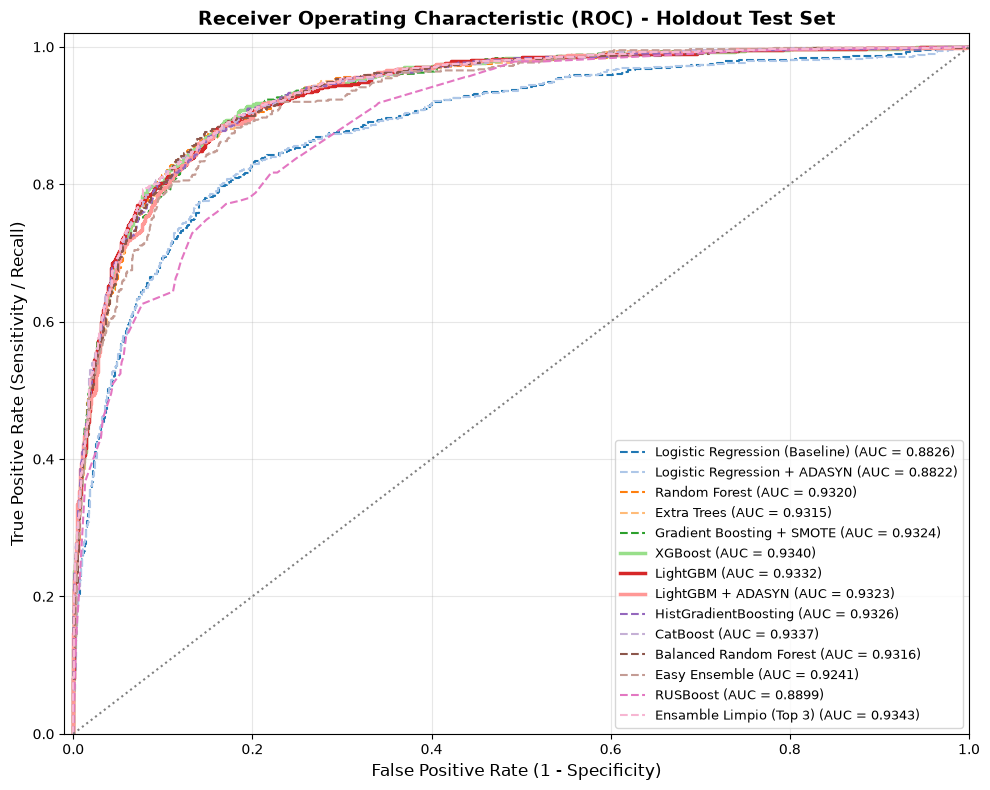

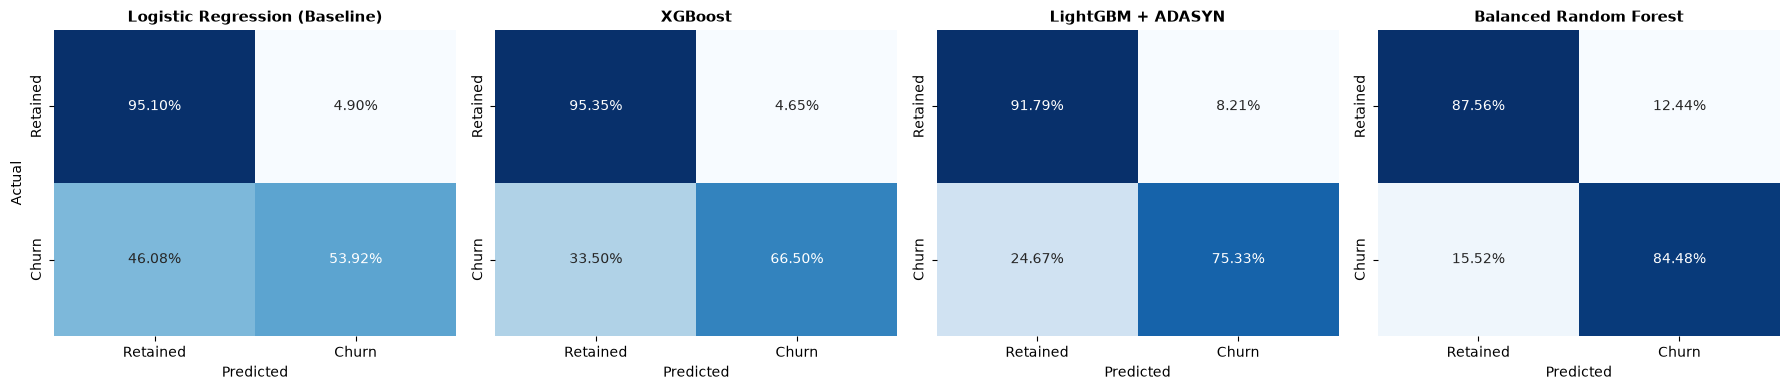

In [8]:
# Create Figures directory
os.makedirs("Figs/cm", exist_ok=True)

# 1. Multi-Model ROC Curves
plt.figure(figsize=(10, 8))
palette = sns.color_palette("tab20", len(eval_data))

for idx, (name, res) in enumerate(eval_data.items()):
    fpr, tpr, _ = roc_curve(y_test, res['y_pred_proba'])
    roc_auc = res['ROC-AUC']
    lw = 2.5 if 'XGBoost' in name or 'LightGBM' in name else 1.5
    linestyle = '-' if 'XGBoost' in name or 'LightGBM' in name else '--'
    plt.plot(fpr, tpr, lw=lw, linestyle=linestyle, color=palette[idx],
             label=f"{name} (AUC = {roc_auc:.4f})")

plt.plot([0, 1], [0, 1], color='gray', lw=1.5, linestyle=':')
plt.xlim([-0.01, 1.0])
plt.ylim([0.0, 1.02])
plt.xlabel("False Positive Rate (1 - Specificity)", fontsize=12)
plt.ylabel("True Positive Rate (Sensitivity / Recall)", fontsize=12)
plt.title("Receiver Operating Characteristic (ROC) - Holdout Test Set", fontsize=14, fontweight='bold')
plt.legend(loc="lower right", fontsize=9, frameon=True)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("Figs/ROC_Curvas_Refactored.png", dpi=300)
plt.show()

# 2. Confusion Matrices for key models
key_models = ['Logistic Regression (Baseline)', 'XGBoost', 'LightGBM + ADASYN', 'Balanced Random Forest']
fig, axes = plt.subplots(1, len(key_models), figsize=(18, 4))

for i, m_name in enumerate(key_models):
    cm = eval_data[m_name]['Confusion Matrix']
    cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='Blues', cbar=False, ax=axes[i],
                xticklabels=['Retained', 'Churn'], yticklabels=['Retained', 'Churn'])
    axes[i].set_title(m_name, fontsize=11, fontweight='bold')
    axes[i].set_xlabel("Predicted")
    axes[i].set_ylabel("Actual" if i == 0 else "")

plt.tight_layout()
plt.savefig("Figs/cm/confusion_matrices_comparison.png", dpi=300)
plt.show()


## 8. Model Interpretability Analysis via SHAP (SHapley Additive exPlanations)

To provide explainability for model predictions, we compute exact Tree SHAP values on the top-performing model (`LightGBM`) to explain:
1. **Global feature importance ranking:** Identifies the primary drivers of customer churn.
2. **Feature attribution directionality:** Explains how variations in age, number of products, active membership, and account balance systematically drive attrition risk.


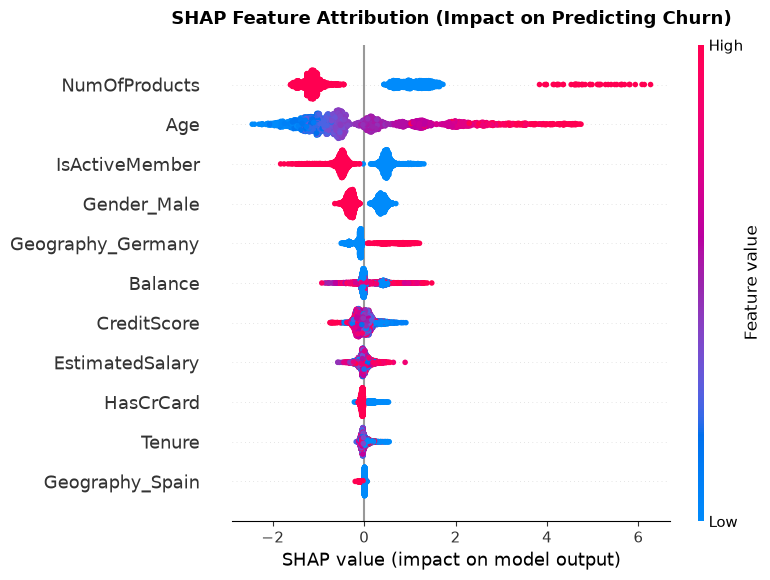


QUANTITATIVE FEATURE IMPORTANCE (SHAP)
 1. NumOfProducts            : 1.1765
 2. Age                      : 1.1623
 3. IsActiveMember           : 0.5207
 4. Gender_Male              : 0.3389
 5. Geography_Germany        : 0.2376
 6. Balance                  : 0.1974
 7. CreditScore              : 0.1429
 8. EstimatedSalary          : 0.0946
 9. HasCrCard                : 0.0777
10. Tenure                   : 0.0591
11. Geography_Spain          : 0.0191


In [9]:
# Fit best model on transformed features for TreeExplainer
best_pipe = models['LightGBM']
preprocessor_fitted = best_pipe.named_steps['preprocessor']
classifier_fitted = best_pipe.named_steps['classifier']

# Extract feature names after One-Hot Encoding
ohe_feature_names = preprocessor_fitted.named_transformers_['cat'].get_feature_names_out(categorical_cols)
all_feature_names = numerical_cols + list(ohe_feature_names)

X_test_trans = preprocessor_fitted.transform(X_test)
X_test_trans_df = pd.DataFrame(X_test_trans, columns=all_feature_names)

# Compute SHAP values
explainer = shap.TreeExplainer(classifier_fitted)
shap_values = explainer.shap_values(X_test_trans_df)

# Handle LightGBM binary classification output format
if isinstance(shap_values, list):
    shap_vals_churn = shap_values[1]
elif len(shap_values.shape) == 3:
    shap_vals_churn = shap_values[:, :, 1]
else:
    shap_vals_churn = shap_values

# 1. SHAP Beeswarm Summary Plot
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_vals_churn, X_test_trans_df, feature_names=all_feature_names, show=False)
plt.title("SHAP Feature Attribution (Impact on Predicting Churn)", fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig("Figs/shap_summary.png", dpi=300, bbox_inches='tight')
plt.show()

# 2. Quantitative Mean Absolute SHAP Importance Ranking
mean_abs_shap = np.abs(shap_vals_churn).mean(axis=0)
df_shap_importance = pd.DataFrame({
    'Feature': all_feature_names,
    'Mean |SHAP Value|': mean_abs_shap
}).sort_values(by='Mean |SHAP Value|', ascending=False).reset_index(drop=True)

print("\n" + "=" * 50)
print("QUANTITATIVE FEATURE IMPORTANCE (SHAP)")
print("=" * 50)
for idx, row in df_shap_importance.iterrows():
    print(f"{idx+1:2d}. {row['Feature']:25s}: {row['Mean |SHAP Value|']:.4f}")


## 9. Kaggle Submission Generator

We generate predictions for the Kaggle unlabelled test set (`Datasets/test.csv`) using the best-performing pipeline.


In [10]:
test_kaggle_path = "/home/ander/Documentos/Universidad/ML/proyecto/Datasets/test.csv"
df_kaggle_test = pd.read_csv(test_kaggle_path)

# Predict probabilities using the top-performing pipeline
test_features = df_kaggle_test[X.columns]
kaggle_pred_proba = best_pipe.predict_proba(test_features)[:, 1]

submission_df = pd.DataFrame({
    'id': df_kaggle_test['id'],
    'Exited': kaggle_pred_proba
})

os.makedirs("Optuna", exist_ok=True)
submission_path = "Optuna/submission_refactored_lgbm.csv"
submission_df.to_csv(submission_path, index=False)
print(f"Kaggle submission successfully exported to '{submission_path}'.")
print(f"Total submission rows: {submission_df.shape[0]}")
print(submission_df.head())


Kaggle submission successfully exported to 'Optuna/submission_refactored_lgbm.csv'.
Total submission rows: 10000
      id    Exited
0  15000  0.045511
1  15001  0.183531
2  15002  0.012039
3  15003  0.860594
4  15004  0.006226
